# Tutorial 1 — CoSMIM on one STARmap section (dataset4)

This notebook runs CoSMIM step by step on the STARmap mouse visual cortex section used as dataset4 in the paper: 1,207 cells, 1,020 genes and seven annotated layers (Wang *et al.*, *Science* 2018). The section and its annotation are the version distributed with SDMBench (Yuan *et al.*, *Nat. Methods* 2024; figshare [10.6084/m9.figshare.22565209](https://doi.org/10.6084/m9.figshare.22565209), CC BY 4.0).

There are two manual annotations. One is "Region", from the original data, and the other is "smoothed_manual".

In [1]:
import sys
sys.path.insert(0, "../src")

import hashlib
import numpy as np
import pandas as pd
import scanpy as sc
import cosmim

## 1. Load data

In [2]:
path = "../data/D4_STARmap_VisualCortex/STARmap_20180505_BY3_1k.h5ad"
# import urllib.request
# urllib.request.urlretrieve("https://ndownloader.figshare.com/files/40038688", path)

adata = sc.read_h5ad(path)
adata

AnnData object with n_obs × n_vars = 1207 × 1020
    obs: 'Total_counts', 'X', 'Y', 'label', 'region', 'Region'
    uns: 'label_colors'
    obsm: 'spatial'

In [3]:
adata.obs["Region"].value_counts()

Region
L2/3    262
L4      230
L6      223
L5      156
CC      154
L1      113
HPC      69
Name: count, dtype: int64

## 2. Preprocessing and gene selection

Cells with fewer than 5 counts and genes detected in fewer than 3 cells are removed, and the counts are normalised to 10,000 per cell and log-transformed. CoSMIM then uses spatially variable genes (Moran's I > 0.05); for this dataset the paper keeps the 64 with the largest Moran's I (`strategy="svg_only"`).

In [4]:
adata_raw, adata_hvg = cosmim.spatial_preprocess_pipeline(adata, strategy="svg_only",
                                                         n_top_hvg=64)
print(adata_raw.shape, adata_hvg.shape)
print(adata_hvg.var_names[:10].tolist())

(1207, 1020) (1207, 64)
['Mbp', 'Mobp', 'Camk2n1', 'Plp1', 'Nrgn', 'Pcp4', 'Tsnax', 'Lamp5', 'Cux2', 'Pgm2l1']


## 3. The CoSMIM feature

For every cell, the gene-gene covariance of its neighbourhood is computed at three scales. The three matrices are fused with weights learned for this section (λ = 10), shrunk towards a scaled identity (α = 0.1), and the lower triangle of the matrix square root is the feature: 64 genes give 64 × 65 / 2 = 2,080 values per cell.

In [5]:
features, weights = cosmim.compute_cosmim(adata_hvg, k=[5, 15, 45], entropy_reg=10, alpha=0.1)
print(features.shape)
print("scale weights (k = 5, 15, 45):", np.round(weights, 6))

(1207, 2080)
scale weights (k = 5, 15, 45): [0.544243 0.257942 0.197815]


## 4. Clustering and the nine metrics

PCA and Leiden clustering, with the resolution searched until the number of clusters equals the number of annotated layers. The nine metrics are those of SDMBench.

In [6]:
n_layers = cosmim.get_num_groups(adata_raw, "Region")
adata_raw.obs["cosmim"] = cosmim.run_leiden_partition(features, max_labels=n_layers,
                                                      n_pcs=30, n_neighbors=200)
metrics = cosmim.calc_all_metrics(adata_raw, gt_key="Region", pred_key="cosmim")
pd.Series(metrics).round(4)

INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        


  0%|          | 0/100 [00:00<?, ?/s]

  0%|          | 0/100 [00:00<?, ?/s]

ARI       0.6389
NMI       0.7310
HOM       0.6775
COM       0.7937
CHAOS     0.0628
PAS       0.0257
ASW       0.5785
MoranI    0.2666
GearyC    0.7395
dtype: float64

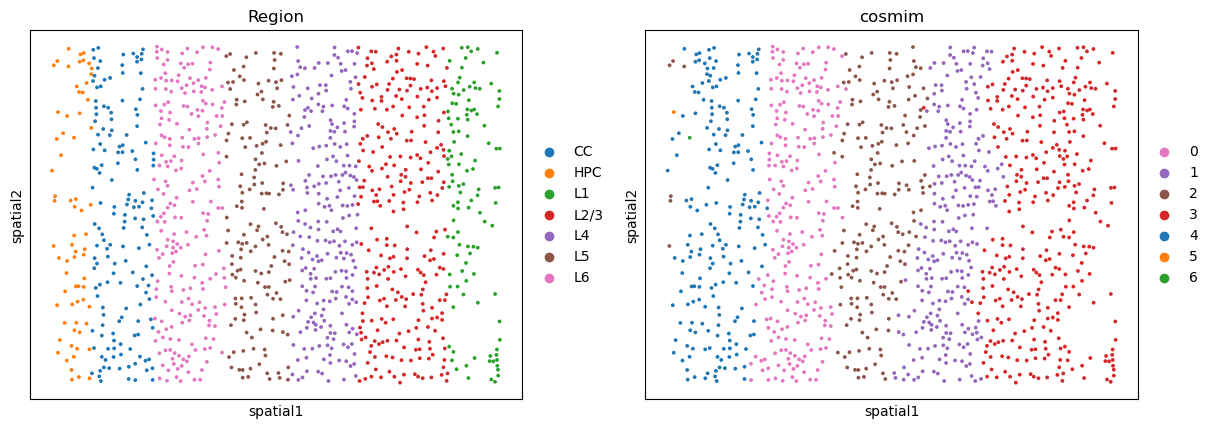

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from scipy.optimize import linear_sum_assignment

# Each cluster takes the colour of the layer it overlaps most, one to one (Hungarian matching)
adata_raw.obs["cosmim"] = adata_raw.obs["cosmim"].astype("category")
overlap = pd.crosstab(adata_raw.obs["cosmim"], adata_raw.obs["Region"])
_, layer = linear_sum_assignment(-overlap.values)
adata_raw.uns["Region_colors"] = [to_hex(c) for c in plt.cm.tab10.colors[:overlap.shape[1]]]
adata_raw.uns["cosmim_colors"] = [adata_raw.uns["Region_colors"][j] for j in layer]
sc.pl.embedding(adata_raw, basis="spatial", color=["Region", "cosmim"], s=30)

## 5. A second annotation: smoothed_manual

BANKSY (Singhal *et al.*, *Nat. Genet.* 2024) also scores this section against a second
annotation, `smoothed_manual`, which its authors derived from the cell types of Wang *et al.* by
label smoothing. Supplementary Table S1 of the paper scores the clusters above against both
annotations (CoSMIM on `smoothed_manual`: NMI 0.775, ARI 0.763). The annotation is a CSV in
the BANKSY repository; the next cell downloads it into `data/D4_STARmap_VisualCortex/`.

The CSV and the SDMBench file both have 1,207 rows, and the first 1,206 are the same cells in
the same order (the CSV's first column numbers the cells from 0, so its row `8` is `Cell_9`).
The last rows are two different cells, `Cell_1389` in the CSV and `Cell_1390` in the SDMBench
file. Like BANKSY's tutorial, the paper assigned the labels by row, so `Cell_1390` carries the
label of `Cell_1389`. The scores on the 1,206 shared cells, matched by name, follow.

In [8]:
import os, urllib.request

url = ("https://raw.githubusercontent.com/prabhakarlab/Banksy_py/"
       "5c977b269fac67c11e7ac9341a454d13024d2044/"
       "data/starmap/Starmap_BY3_1k_meta_annotated_18oct22.csv")
path = "../data/D4_STARmap_VisualCortex/Starmap_BY3_1k_meta_annotated_18oct22.csv"
if not os.path.exists(path):
    urllib.request.urlretrieve(url, path)
assert hashlib.md5(open(path, "rb").read()).hexdigest() == "c92c3877efc202a96919bde84fd8e0e4"
smoothed = pd.read_csv(path, index_col=0)
smoothed.index = "Cell_" + (smoothed.index + 1).astype(str)
same = smoothed.index == adata_raw.obs_names
print(same.sum(), "of", len(same), "rows are the same cell; the last rows are",
      smoothed.index[-1], "(CSV) and", adata_raw.obs_names[-1], "(SDMBench)")

1206 of 1207 rows are the same cell; the last rows are Cell_1389 (CSV) and Cell_1390 (SDMBench)


In [9]:
adata_raw.obs["smoothed_manual"] = pd.Categorical(
    smoothed["smoothed_manual"].values, categories=["cc", "HPC", "L1", "L2/3", "L4", "L5", "L6"])
assert adata_raw.obs["smoothed_manual"].notna().all()
metrics_smoothed = cosmim.calc_all_metrics(adata_raw, gt_key="smoothed_manual", pred_key="cosmim")
pd.DataFrame({"Region": metrics, "smoothed_manual": metrics_smoothed}).round(4)

INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        


  0%|          | 0/100 [00:00<?, ?/s]

  0%|          | 0/100 [00:00<?, ?/s]

,Region,smoothed_manual
ARI,0.6389,0.7627
NMI,0.7310,0.7748
HOM,0.6775,0.7355
COM,0.7937,0.8186
CHAOS,0.0628,0.0628
PAS,0.0257,0.0257
ASW,0.5785,0.5785
MoranI,0.2666,0.2666
GearyC,0.7395,0.7395


In [10]:
adata_raw.obs["smoothed_by_name"] = smoothed["smoothed_manual"].reindex(adata_raw.obs_names).values
shared = adata_raw[adata_raw.obs["smoothed_by_name"].notna()]
print(shared.n_obs, "cells matched by name:",
      "NMI", round(cosmim.calc_nmi(shared, "smoothed_by_name", "cosmim"), 4),
      " ARI", round(cosmim.calc_ari(shared, "smoothed_by_name", "cosmim"), 4))

1206 cells matched by name: NMI 0.7766  ARI 0.7648


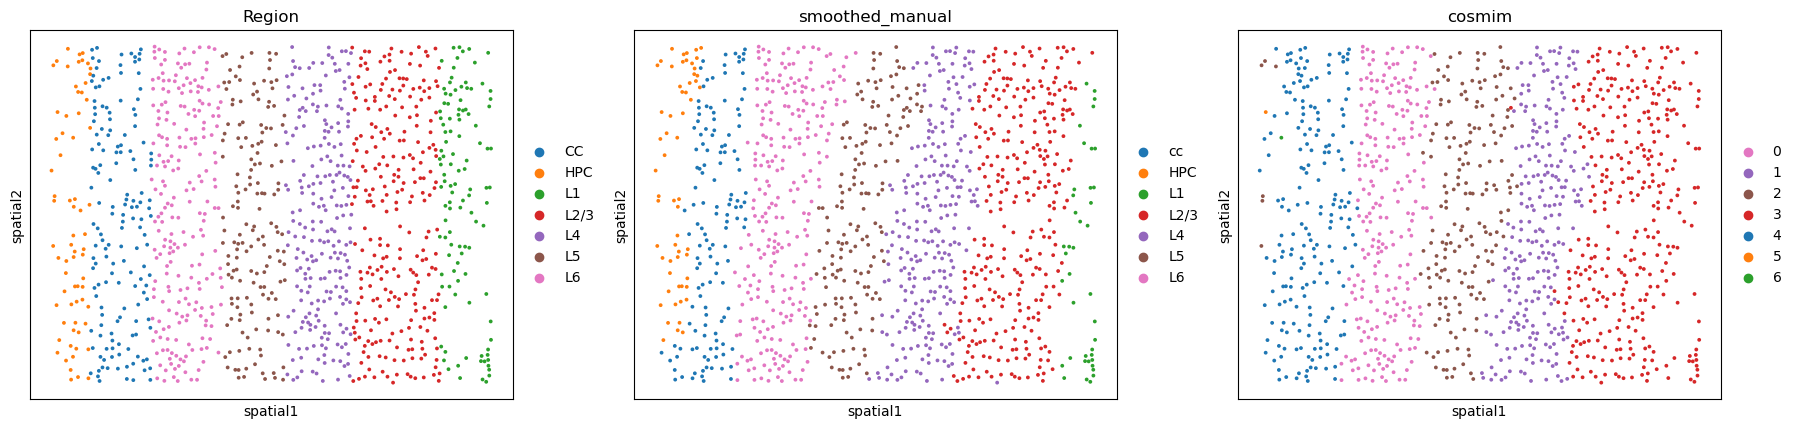

In [11]:
sc.pl.embedding(adata_raw, basis="spatial", color=["Region", "smoothed_manual", "cosmim"], s=30)

## 6. In one call

`cosmim.run` does all of the above for one section. Other settings of `compute_cosmim` can
be passed through it, for example `feature_transform="logm"` (the matrix logarithm instead of
the square root), `weights=[1/3, 1/3, 1/3]` (fixed weights), `cov_type="traditional"` (centre
each niche on its own mean) or `exclude_target=True` (leave the cell out of its niche).

In [12]:
result = cosmim.run(adata, annotation_key="Region", strategy="svg_only", n_top_hvg=64,
                    n_pcs=30, n_neighbors=200)
{key: result.uns["cosmim"][key] for key in ["NMI", "ARI", "weights", "resolution"]}

{'NMI': 0.7309728442261789,
 'ARI': 0.6389355431912271,
 'weights': array([0.54424273, 0.25794226, 0.197815  ]),
 'resolution': 1.3}